# El protocolo con campaña fuera y criterio predeclarado: lo que revela una campaña fuera y oculta una partición aleatoria

**Pregunta:** ¿Algún predictor supera el criterio predeclarado cuando se dejan campañas completas fuera?

**Nivel 4: Más allá del estado del arte** · Requiere: 04-benchmark-protocol/02-scores-the-null-and-the-interval, 04-benchmark-protocol/03-placing-a-published-score-in-its-own-protocol · Tiempo de lectura: unos 45 minutos

## Objetivos

La afirmación BS-1 del producto es un protocolo y no un modelo: el nivel aprendido se juzga con campañas completas fuera, con intervalos que remuestrean campañas, y frente a un criterio escrito antes de la corrida. Este notebook corre ese protocolo en todos los predictores de la escalera y plantea la pregunta que el criterio existe para responder.

Al terminar habrá:

- reajustado gradient boosting pliegue a pliegue y leído el error de cada campaña fuera;
- corrido los once predictores de la escalera y el nulo bajo el protocolo y medido lo que le cuesta a cada uno frente a una partición aleatoria;
- dibujado el intervalo de todo predictor, remuestreando campañas, como gráfico de bosque en ambos conjuntos de filas;
- aplicado el criterio, palabra por palabra, al mejor predictor aprendido en 97 y en 91 tiros, y comparado todo con lo que versionó la ejecución offline.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Una sola celda hace toda la preparación: importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número que sigue, define el ayudante de tablas y carga los 97 tiros de entrenamiento.

In [1]:
# Importaciones, las versiones detrás de cada número, un ayudante de tablas y el corpus
import json
from importlib.metadata import version
from pathlib import Path
import hashlib
import textwrap

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas no forma parte del entorno de notebooks, así que una tabla es una tabla HTML simple
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


BENCHMARK = Path("../../../data/derived/benchmark.json")
train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| El benchmark versionado, leído una vez para la verificación del final | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json` |

Todo puntaje, intervalo y brecha que el notebook discute se recalcula reajustando los predictores sobre el corpus; el benchmark versionado aparece solo en el último paso.

## Método

El protocolo tiene cuatro partes, y cada una es una decisión que una celda de abajo ejecuta.

1. **Dejar fuera la campaña.** Un pliegue por campaña, las otras nueve en entrenamiento, el nulo reajustado en cada pliegue.
2. **Informar la brecha.** Para cada predictor, la mediana del puntaje de 100 particiones aleatorias 80/20 menos su puntaje agrupado con la campaña fuera, de modo que el costo del protocolo sea un número y no una impresión.
3. **Remuestrear la unidad correcta.** Los intervalos extraen campañas, no tiros, 2000 veces.
4. **Declarar primero el criterio.** La oración que decide si el nivel aprendido generaliza se fija antes de la corrida, y su hash queda fijado en las pruebas del motor.

El puntaje es `r2_identity` en todo el notebook. Qué mirar en los dos primeros pasos: qué campañas se equivoca el predictor con la campaña fuera, en qué sentido, y qué tan ancho es un intervalo honesto para el puntaje agrupado.

### Paso 1: gradient boosting, pliegue a pliegue

La celda reajusta gradient boosting y el nulo con nueve campañas en cada uno de los diez pliegues, predice la décima y guarda las predicciones fuera de pliegue. La tabla da, para cada campaña, el tamaño medio medido, el tamaño medio predicho, el sesgo y la raíz del error cuadrático medio de ese pliegue: de ahí sale el puntaje agrupado.

In [2]:
# Gradient boosting reajustado pliegue a pliegue con la campaña fuera, y el nulo reajustado a su lado
factories = bf.default_arms()
folds = list(bf.leave_one_site_out(train))
tested, boosted, null = [], [], []
rows, campaign_means = [], {}
for fold in folds:
    out = factories["xgboost"]().fit(fold.train).predict(fold.test)
    tested += list(fold.test)
    boosted += out
    null += factories["null"]().fit(fold.train).predict(fold.test)
    measured = np.mean([blast.x50_m for blast in fold.test])
    predicted = np.mean([p.x50_m for p in out])
    site = fold.detail["held_out_site"]
    campaign_means[site] = (measured, predicted)
    error = bf.score(fold.test, out).rmse_m
    sizes = (len(fold.train), len(fold.test))
    means = [f"{value:.3f}" for value in (measured, predicted)]
    rows.append((site, *sizes, *means, f"{predicted - measured:+.3f}", f"{error:.3f}"))
show_table(["campaña fuera", "entrenamiento", "prueba",
            "medio medido (m)", "medio predicho (m)",
            "sesgo (m)", "RMSE (m)"], rows)

campaña fuera,entrenamiento,prueba,medio medido (m),medio predicho (m),sesgo (m),RMSE (m)
Akdaglar,75,22,0.171,0.245,+0.074,0.088
Dongri-Buzurg,88,9,0.413,0.260,-0.153,0.225
Enusa,85,12,0.396,0.463,+0.067,0.114
Miami,91,6,0.080,0.378,+0.298,0.300
Mrica,86,11,0.166,0.257,+0.090,0.100
Murgul,90,7,0.311,0.672,+0.360,0.365
Ozmert,90,7,0.191,0.167,-0.024,0.089
Reocin,87,10,0.616,0.382,-0.234,0.314
Reocin-UG,91,6,0.593,0.553,-0.040,0.080
Soma,90,7,0.224,0.126,-0.099,0.106


El error está concentrado. Los menores errores de pliegue son Reocin-UG con 0,080 m, Ozmert con 0,089 m y Akdaglar con 0,088 m, esta última con los 22 tiros que la hacen la campaña más grande, mientras que Murgul con 0,365 m, Miami con 0,300 m y Reocin con 0,314 m son varias veces mayores. Los sesgos tienen un patrón: la campaña más fina, Miami, se predice en 0,378 m frente a 0,080 m medido (+0,298), y la más gruesa, Reocin, en 0,382 m frente a 0,616 m (-0,234), de modo que el modelo acerca una campaña al centro del corpus; Murgul rompe el patrón, una campaña de tamaño medio predicha en 0,672 m frente a 0,311 m (+0,360). La tabla no dice por qué falla Murgul, solo que un modelo entrenado con las otras nueve campañas no tiene nada que se le parezca.

### Paso 2: el puntaje agrupado y el intervalo honesto

Los diez pliegues se agrupan en 97 predicciones fuera de pliegue y se puntúan una vez. El intervalo es el bootstrap de 95 por ciento que remuestrea campañas completas, con 2000 extracciones y una semilla fija, la unidad que es independiente bajo este protocolo.

In [3]:
# Agrupar los diez pliegues, puntuar gradient boosting y el nulo, y calcular el intervalo que remuestrea campañas
boosted_score = bf.score(tested, boosted)
null_score = bf.score(tested, null)
point, low, high = bf.bootstrap_interval(tested, boosted, "r2_identity", n_boot=2000, unit="site", seed=0)
interval = f"{low:.3f} a {high:.3f}"
rows = []
for label, score, ends in (("gradient boosting", boosted_score, interval),
                           ("nulo (media de entrenamiento)", null_score, "-")):
    rows.append((label, f"{score.r2_identity:.4f}", f"{score.rmse_m:.4f}", ends))
show_table(["predictor", "r2_identity", "RMSE (m)",
            "intervalo de 95 %, campañas remuestreadas"], rows)
print(f"tiros puntuados: {len(tested)} | campañas: {len(folds)} | extracciones: 2000")

predictor,r2_identity,RMSE (m),"intervalo de 95 %, campañas remuestreadas"
gradient boosting,-0.0342,0.1906,-2.232 a 0.418
nulo (media de entrenamiento),-0.2163,0.2067,-


tiros puntuados: 97 | campañas: 10 | extracciones: 2000


Agrupado en los 97 tiros, gradient boosting puntúa -0,0342 y el nulo -0,2163, con raíces del error cuadrático medio de 0,1906 m y 0,2067 m. Una constante igual al promedio global de las mediciones puntuaría exactamente cero, de modo que el modelo es algo peor que esa constante, y va por delante del nulo solo porque el propio nulo es tirado en el sentido equivocado por la media de entrenamiento. El intervalo por campañas va de -2,232 a 0,418 y contiene el cero con holgura. La celda no dice que el modelo sea inútil: dice que con diez campañas la evidencia no puede distinguir este modelo de una constante.

## Estado del arte

- Los predictores aprendidos publicados sobre este corpus (Sui et al. 2025, https://doi.org/10.3390/app15031254) reportan un puntaje de una sola partición aleatoria 80/20.
- La base de investigación del SDD anota que los resúmenes de los estudios de predictores aprendidos (Chen et al. 2025, https://doi.org/10.1007/s00521-025-11321-3; Gebretsadik et al. 2024, https://doi.org/10.1007/s42452-024-05888-0) no dicen que se dejara fuera una mina completa, y que los predictores publicados son de un solo sitio.
- El remuestreo agrupado es el remedio establecido cuando los datos son dependientes (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

El notebook anterior corrió el primero de estos en el motor y encontró que su 0,943 no es una partición típica de su propio protocolo. Lo que la literatura no ofrece es una manera de decir si un predictor aprendido se transfiere a una campaña que no ha visto, con una incertidumbre que cuenta campañas y un veredicto cuya redacción no se puede ajustar después. Ese es el vacío que llena la sección siguiente.

## Más allá del estado del arte

La afirmación BS-1 es evidencia de cuatro cosas a la vez: el costo de la pregunta del profesional como número, un intervalo que no lo exagera, un recuento por campaña de dónde fallan los predictores, y un veredicto fijado de antemano. Los pasos que siguen producen cada una desde una corrida de toda la escalera: los predictores clásicos, estadísticos y aprendidos, y el nulo, todos con la campaña fuera.

### Paso 3: toda la escalera, cada campaña fuera

La celda repite los diez pliegues para cada predictor de la escalera salvo el oráculo, que ve la respuesta, y el discriminante de grupo, que se abstiene en todo tiro. La tabla da el nivel de cada predictor, cuántos tiros puntuó y cuántos se negó a responder, y su puntaje agrupado en lo que respondió.

In [4]:
# Todo predictor de la escalera, cada campaña fuera por turno
ladder = [name for name in factories if name not in ("oracle", "group-discriminant")]
tiers = {name: factories[name]().tier for name in ladder}
held = {name: [] for name in ladder}
for fold in folds:
    for name in ladder:
        held[name] += factories[name]().fit(fold.train).predict(fold.test)
rows = []
for name in ladder:
    score = bf.score(tested, held[name])
    rows.append((name, tiers[name], score.n_scored, score.n_abstained, f"{score.r2_identity:.4f}"))
show_table(["predictor", "nivel", "tiros puntuados", "abstenciones", "r2_identity"], rows)

predictor,nivel,tiros puntuados,abstenciones,r2_identity
null,control,97,0,-0.2163
kuznetsov,classical,91,6,0.3112
kuznetsov-transfer,classical,91,6,0.2982
kuznetsov-capped,classical,91,6,0.3523
published-regression,statistical,97,0,0.8018
refitted-regression,statistical,93,4,-4.0746
published-neural-net,learned,97,0,-0.6256
svr-rbf,learned,96,1,-0.3868
svr-poly,learned,86,11,-4.5457
random-forest,learned,97,0,-0.2315


La escalera se divide en tres grupos. Todo predictor aprendido está bajo cero: -0,0342 para gradient boosting, -0,0345 para el apilamiento, -0,2315 para el bosque aleatorio, -0,3868 para la regresión de vectores soporte con núcleo radial, -0,6256 para la red publicada y -4,5457 para la de núcleo polinómico, que además rechaza 11 tiros. Las tres variantes clásicas puntúan 0,3112, 0,2982 y 0,3523 en los 91 tiros que responden, y se abstienen en 6. La regresión publicada puntúa 0,8018, pero su fuente la ajustó con los 97 de estos tiros, de modo que ninguna partición le oculta un tiro. La tabla no dice que la ecuación clásica se transfiera libremente: dos de sus variantes usan una constante por campaña, y solo `kuznetsov-transfer`, con 0,2982, no usa nada de la campaña objetivo.

### Paso 4: lo que cuesta el protocolo

Para cada predictor la celda dibuja las 100 particiones aleatorias 80/20 del paso 2 del notebook anterior, toma la mediana del puntaje y le resta el puntaje con la campaña fuera. La red neuronal publicada queda fuera de las particiones aleatorias porque 100 reajustes suyos toman cerca de tres minutos; su puntaje con la campaña fuera está en todas las demás tablas.

In [5]:
# La mediana de 100 particiones aleatorias de cada predictor, y la brecha a su puntaje con campaña fuera
random_draws = bf.repeated_random_splits(train, n_repeats=100, seed=0)
skipped = "published-neural-net"  # 100 reajustes toman cerca de tres minutos
random_median = {}
for name in ladder:
    if name == skipped:
        continue
    values = []
    for draw in random_draws:
        model = factories[name]().fit(draw.train)
        values.append(bf.score(draw.test, model.predict(draw.test)).r2_identity)
    random_median[name] = np.median([v for v in values if v is not None])
held_score = {name: bf.score(tested, held[name]).r2_identity for name in ladder}
gap = {name: random_median[name] - held_score[name] for name in random_median}
rows = []
for name in sorted(gap, key=gap.get, reverse=True):
    rows.append((name, tiers[name], f"{random_median[name]:.3f}", f"{held_score[name]:.3f}", f"{gap[name]:.3f}"))
show_table(["predictor", "nivel", "mediana aleatoria",
            "campaña fuera", "brecha"], rows)
learned = [name for name in gap if tiers[name] == "learned"]
median_gap = np.median([gap[name] for name in learned])
print(f"brecha mediana, predictores aprendidos corridos ({len(learned)}): {median_gap:.3f}")

predictor,nivel,mediana aleatoria,campaña fuera,brecha
svr-poly,learned,0.395,-4.546,4.940
refitted-regression,statistical,0.686,-4.075,4.760
svr-rbf,learned,0.665,-0.387,1.052
random-forest,learned,0.749,-0.231,0.981
xgboost,learned,0.704,-0.034,0.738
stacking,learned,0.703,-0.035,0.738
null,control,-0.036,-0.216,0.180
kuznetsov-capped,classical,0.399,0.352,0.047
kuznetsov-transfer,classical,0.312,0.298,0.014
published-regression,statistical,0.805,0.802,0.003


brecha mediana, predictores aprendidos corridos (5): 0.981


Para los cinco predictores aprendidos corridos, la brecha va de 0,738 para gradient boosting y el apilamiento a 4,940 para la regresión de núcleo polinómico, con una mediana de 0,981, y sus medianas aleatorias están entre 0,665 y 0,749 salvo la polinómica con 0,395. Las variantes clásicas pierden casi nada, 0,047, 0,014 y -0,009, y también la regresión publicada con 0,003, que no tiene nada que perder porque se ajustó con todos los tiros. La red falta en esta tabla por decisión, no por omisión. La tabla no dice que la mediana aleatoria sea un puntaje justo, solo que el protocolo es lo que la mueve.

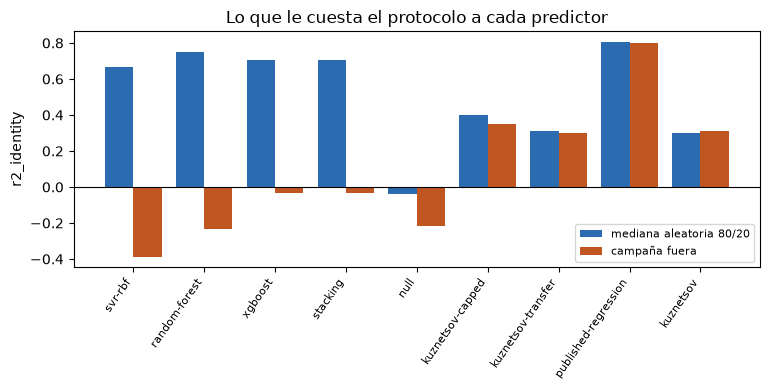

fuera de la figura, puntaje con campaña fuera bajo -1: ['refitted-regression', 'svr-poly']


In [6]:
# La brecha como figura: mediana aleatoria frente a puntaje con campaña fuera, un par de barras por predictor
shown = [name for name in sorted(gap, key=gap.get, reverse=True) if held_score[name] > -1]
fig, ax = plt.subplots(figsize=(7.8, 4.0))
position = np.arange(len(shown))
ax.bar(position - 0.2, [random_median[n] for n in shown], 0.4, color="#2b6cb0",
       label="mediana aleatoria 80/20")
ax.bar(position + 0.2, [held_score[n] for n in shown], 0.4, color="#c05621",
       label="campaña fuera")
ax.set_xticks(position, shown, rotation=55, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("r2_identity")
ax.set_title("Lo que le cuesta el protocolo a cada predictor")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("fuera de la figura, puntaje con campaña fuera bajo -1:", [n for n in gap if n not in shown])

Cada barra azul es lo que reporta una partición aleatoria 80/20 y cada barra naranja lo que puntúa el mismo predictor con la campaña fuera. Para los predictores aprendidos las barras azules están entre 0,665 y 0,749 y las naranjas caen a cero o bajo cero, mientras que para las variantes clásicas y la regresión publicada las dos barras tienen casi la misma altura. Los dos predictores cuyo puntaje con la campaña fuera queda bajo -1, la regresión reajustada y la regresión de núcleo polinómico, se dejan fuera del gráfico para que los demás sigan legibles, y la celda imprime sus nombres. La figura muestra lo que cuesta el protocolo; no muestra si el número de la partición aleatoria fue alguna vez una estimación justa para una mina nueva.

### Paso 5: los intervalos que remuestrean campañas

Para cada predictor y para cada uno de los dos conjuntos de filas, `all` (97 tiros) y `geometry` (los 91 tiros en los que la ecuación clásica puede responder), la celda calcula el intervalo de 95 por ciento con 2000 remuestreos de campañas. Lista los extremos y marca los predictores cuyo extremo inferior queda sobre cero, y el predictor que su fuente ajustó con estos mismos tiros, al que ninguna partición puede ocultarle un tiro.

In [7]:
# El intervalo de todo predictor, remuestreando campañas, en ambos conjuntos de filas
intervals = {}
for name in ladder:
    for support, keep in bf.SUPPORTS.items():
        kept = [i for i, blast in enumerate(tested) if keep(blast)]
        chosen = [tested[i] for i in kept]
        chosen_predictions = [held[name][i] for i in kept]
        intervals[name, support] = bf.bootstrap_interval(
            chosen, chosen_predictions, "r2_identity", n_boot=2000, unit="site", seed=0)
in_sample = [name for name in ladder if factories[name]().in_sample_corpus]
rows = []
for name in ladder:
    if name == "null":
        continue
    ends = [f"{intervals[name, s][1]:.2f} a {intervals[name, s][2]:.2f}" for s in bf.SUPPORTS]
    above = [s for s in bf.SUPPORTS if intervals[name, s][1] > 0]
    rows.append((name, tiers[name], *ends, ", ".join(above) or "-", "sí" if name in in_sample else ""))
show_table(["predictor", "nivel", "all 97", "geometry 91",
            "extremo inferior sobre cero",
            "ajustado con estos tiros"], rows)

predictor,nivel,all 97,geometry 91,extremo inferior sobre cero,ajustado con estos tiros
kuznetsov,classical,-0.96 a 0.70,-0.97 a 0.69,-,
kuznetsov-transfer,classical,-1.10 a 0.72,-1.10 a 0.71,-,
kuznetsov-capped,classical,-0.95 a 0.74,-0.96 a 0.73,-,
published-regression,statistical,0.57 a 0.90,0.50 a 0.88,"all, geometry",sí
refitted-regression,statistical,-19.48 a 0.02,-21.92 a 0.09,-,
published-neural-net,learned,-3.35 a 0.01,-3.42 a 0.09,-,
svr-rbf,learned,-1.61 a -0.06,-1.86 a -0.07,-,
svr-poly,learned,-16.24 a -0.83,-17.18 a -0.95,-,
random-forest,learned,-2.78 a 0.38,-2.88 a 0.40,-,
xgboost,learned,-2.23 a 0.42,-1.78 a 0.53,-,


Con las campañas remuestreadas, ningún predictor aprendido tiene un intervalo cuyo extremo inferior esté sobre cero en ninguno de los dos conjuntos de filas. Gradient boosting va de -2,23 a 0,42 en 97 tiros y de -1,78 a 0,53 en 91, el apilamiento de -2,25 a 0,42 y de -1,81 a 0,54, y la red publicada de -3,35 a 0,01 y de -3,42 a 0,09. Las dos regresiones de vectores soporte quedan por completo bajo cero: de -1,61 a -0,06 con núcleo radial y de -16,24 a -0,83 con el polinómico. Las variantes clásicas también contienen el cero (de -0,96 a 0,70 para la ecuación base). El único intervalo sobre cero, de 0,57 a 0,90, pertenece a la regresión publicada, que la última columna marca como ajustada con estos tiros. La tabla no dice que los predictores clásicos o aprendidos no tengan habilidad, solo que diez campañas no pueden mostrarla.

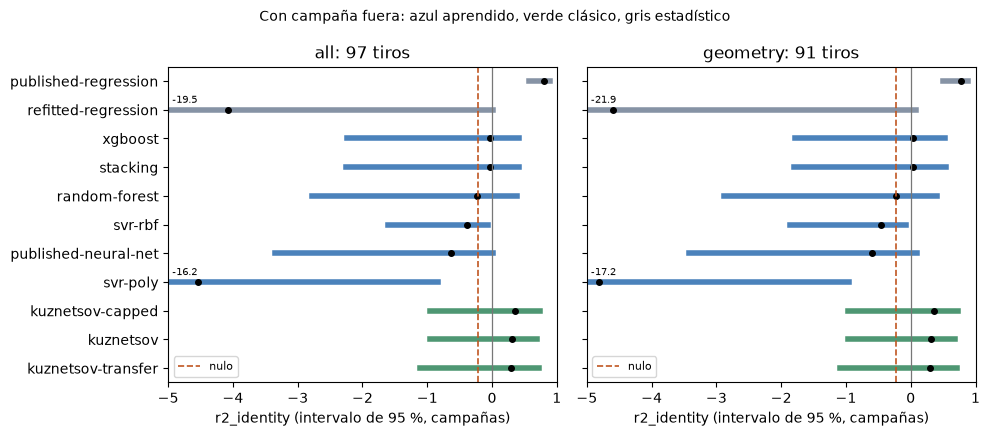

In [8]:
# El gráfico de bosque: el intervalo de cada predictor, ambos conjuntos de filas, el nulo como línea de referencia
colors = {"classical": "#2f855a", "statistical": "#718096", "learned": "#2b6cb0"}
names = sorted((n for n in ladder if n != "null"), key=lambda n: (tiers[n], intervals[n, "all"][0]))
floor = -5.0
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.4), sharey=True)
for ax, support in zip(axes, bf.SUPPORTS):
    for row, name in enumerate(names):
        point, low, high = intervals[name, support]
        ax.plot([max(low, floor), high], [row, row], lw=4, color=colors[tiers[name]], alpha=0.85)
        ax.plot([point], [row], "o", color="black", ms=4)
        if low < floor:
            ax.annotate(f"{low:.1f}", (floor, row), xytext=(3, 5), textcoords="offset points", fontsize=7)
    ax.axvline(0, color="#777", lw=0.9)
    ax.axvline(intervals["null", support][0], color="#c05621", lw=1.2, ls="--", label="nulo")
    ax.set_xlim(floor, 1.0)
    ax.set_xlabel("r2_identity (intervalo de 95 %, campañas)")
    ax.set_title(f"{support}: {len([b for b in tested if bf.SUPPORTS[support](b)])} tiros")
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_yticks(range(len(names)), names)
fig.suptitle("Con campaña fuera: azul aprendido, verde clásico, gris estadístico", fontsize=10)
fig.tight_layout()
plt.show()

El gráfico de bosque hace visible la tabla: todo intervalo azul cruza el cero salvo las dos regresiones de vectores soporte, cuyos intervalos quedan a su izquierda, y la línea discontinua del nulo, en -0,2163 en 97 tiros, cae dentro de casi todos los intervalos, así que la mayoría de los predictores no se pueden separar de él. El intervalo gris de la regresión publicada es el único a la derecha del cero. La regresión reajustada y la regresión de vectores soporte polinómica se cortan en -5 y se rotulan con sus extremos inferiores reales, -19,5 y -16,2. Los dos paneles son casi iguales, de modo que quitar los seis tiros de Miami no cambia el cuadro. La figura muestra superposición entre intervalos, no el tamaño de ninguna diferencia, y un intervalo ancho significa que los datos no informan, no que el modelo sea malo.

### Paso 6: el criterio, aplicado

La celda imprime el criterio exactamente como lo tiene el motor, con los primeros caracteres de su hash, y luego aplica ambas mitades al mejor predictor aprendido en cada conjunto de filas: el puntaje debe estar sobre cero, y al menos 0,10 sobre el del nulo. También nombra la campaña que separa los dos conjuntos de filas.

In [9]:
# El criterio predeclarado, textual, y luego aplicado al mejor predictor aprendido en cada conjunto de filas
print(textwrap.fill(bf.KILL_CRITERION, 110))
print("sha256, primeros 12 caracteres:", hashlib.sha256(bf.KILL_CRITERION.encode()).hexdigest()[:12])
learned = [name for name in ladder if tiers[name] == "learned"]
rows = []
for support, keep in bf.SUPPORTS.items():
    kept = [i for i, blast in enumerate(tested) if keep(blast)]
    r2 = {n: bf.score([tested[i] for i in kept], [held[n][i] for i in kept]).r2_identity for n in [*learned, "null"]}
    best = max(learned, key=r2.get)
    margin = r2[best] - r2["null"]
    met = r2[best] > 0 and margin >= 0.10
    low, high = intervals[best, support][1:]
    values = [f"{r2[best]:.4f}", f"{r2['null']:.4f}", f"{margin:.4f}"]
    rows.append((support, len(kept), best, *values, r2[best] > 0, margin >= 0.10, met, f"{low:.2f} a {high:.2f}"))
show_table(["filas", "n", "mejor aprendido", "r2_identity", "nulo", "margen",
            "> 0", ">= 0.10", "criterio cumplido", "intervalo de 95 %"], rows)
outside = sorted({blast.site for blast in train if not bf.has_absolute_geometry(blast)})
print("campañas fuera del conjunto de filas con geometría:", outside)

The learned tier counts as generalising across sites only if the best learned arm's variance explained under
leave-one-site-out is BOTH positive and at least 0.10 above the null model's. Both halves are required: a
margin over a null that is itself deeply negative is not skill, it is two models failing by different amounts.
sha256, primeros 12 caracteres: a13f11385ef8


filas,n,mejor aprendido,r2_identity,nulo,margen,> 0,>= 0.10,criterio cumplido,intervalo de 95 %
all,97,xgboost,-0.0342,-0.2163,0.1821,False,True,False,-2.23 a 0.42
geometry,91,stacking,0.0343,-0.2320,0.2663,True,True,True,-1.81 a 0.54


campañas fuera del conjunto de filas con geometría: ['Miami']


Aplicado a la letra, el criterio da dos respuestas. En los 97 tiros el mejor predictor aprendido es gradient boosting con -0,0342, que cumple el margen, 0,1821 sobre un nulo en -0,2163, pero no es positivo, de modo que el criterio no se cumple. En los 91 tiros con geometría el mejor es el apilamiento con 0,0343, que es positivo y está 0,2663 sobre un nulo en -0,2320, de modo que el criterio se cumple. La campaña que separa los dos conjuntos es Miami, que no publica diámetro de taladro, y el veredicto depende de si sus seis tiros se cuentan. La mitad del margen se cumple en ambos conjuntos porque el nulo es profundamente negativo, que es exactamente el caso del que protege la segunda mitad de la oración. La tabla no dice que el apilamiento con 0,0343 tenga habilidad: su intervalo en ese conjunto de filas, de -1,81 a 0,54, contiene el cero.

### Paso 7: dónde falla el predictor con la campaña fuera

Un puntaje agrupado oculta qué campañas están equivocadas. La celda grafica, para cada campaña, el tamaño medio que predijo gradient boosting cuando estaba fuera frente al tamaño medio medido, con los números del primer paso.

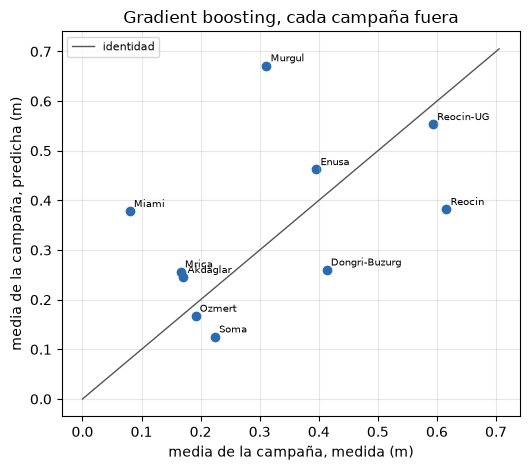

In [10]:
# Dónde falla gradient boosting con la campaña fuera: media de campaña predicha contra medida
sites = list(campaign_means)
measured_means = [campaign_means[site][0] for site in sites]
predicted_means = [campaign_means[site][1] for site in sites]
fig, ax = plt.subplots(figsize=(5.4, 4.8))
ax.scatter(measured_means, predicted_means, color="#2b6cb0")
for site, x, y in zip(sites, measured_means, predicted_means):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
limit = max(measured_means + predicted_means) * 1.05
ax.plot([0, limit], [0, limit], color="#555", lw=1, label="identidad")
ax.set_xlabel("media de la campaña, medida (m)")
ax.set_ylabel("media de la campaña, predicha (m)")
ax.set_title("Gradient boosting, cada campaña fuera")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Los puntos sobre la línea serían campañas predichas correctamente. Miami con 0,080 m medidos y Murgul con 0,311 m quedan bien sobre ella, predichas en 0,378 m y 0,672 m, mientras Reocin con 0,616 m y Dongri-Buzurg con 0,413 m quedan bajo ella, predichas en 0,382 m y 0,260 m, y las campañas grandes Akdaglar, Mrica y Enusa quedan cerca. Las predicciones abarcan solo de 0,126 m a 0,672 m aunque las medias de campaña medidas abarcan de 0,080 m a 0,616 m, de modo que el modelo comprime las campañas hacia un valor medio, y por eso el margen sobre un nulo que se mueve en sentido contrario es fácil de obtener. La figura muestra medias de campaña y oculta los tiros dentro de cada una, así que no puede decir cómo se reparte el error dentro de una.

### Verificación contra el benchmark versionado

La única comparación con un artefacto versionado en este notebook: los puntajes, los extremos de intervalo y las brechas de protocolo calculados aquí se contrastan con los que la ejecución offline escribió en `benchmark.json`, junto con el texto del criterio.

In [11]:
# Verificación: puntajes, intervalos y veredicto son iguales a lo que versionó la ejecución offline
committed = json.loads(BENCHMARK.read_text(encoding="utf-8"))
loso = committed["protocols"]["leave-one-site-out"]["arms"]
verdict = committed["verdict"]
score_gap = max(abs(held_score[n] - loso[n]["r2_identity"]) for n in ladder)
interval_gap = 0.0
for name, both in verdict["intervals_95"].items():
    for support, ends in both.items():
        if ends:
            low, high = intervals[name, support][1:]
            interval_gap = max(interval_gap, abs(low - ends[0]), abs(high - ends[1]))
gaps = verdict["protocol_gap_random_minus_grouped"]
gap_gap = max(abs(gap[n] - gaps[n]) for n in gaps if n in gap)
print(f"mayor diferencia, puntajes con campaña fuera: {score_gap:.1e}")
print(f"mayor diferencia, extremos de intervalo: {interval_gap:.1e}")
print(f"mayor diferencia, brechas de protocolo: {gap_gap:.1e}")
print("mismo texto del criterio:", bf.KILL_CRITERION == committed["kill_criterion"])

mayor diferencia, puntajes con campaña fuera: 0.0e+00
mayor diferencia, extremos de intervalo: 0.0e+00
mayor diferencia, brechas de protocolo: 0.0e+00
mismo texto del criterio: True


## Resultados

**Respuesta:** a la letra del criterio, en 97 tiros ningún predictor lo cumple y en 91 uno sí, y en ningún caso la evidencia separa a un predictor aprendido de una constante. En los 97 tiros el mejor predictor aprendido es gradient boosting con -0,0342, que no es positivo, aunque está 0,1821 sobre el nulo; en los 91 tiros con geometría es el apilamiento con 0,0343, 0,2663 sobre el nulo, y el criterio se cumple. Ningún predictor aprendido tiene un intervalo por campañas cuyo extremo inferior esté sobre cero (gradient boosting de -2,23 a 0,42, apilamiento de -1,81 a 0,54 en 91), y el único intervalo sobre cero, de 0,57 a 0,90, pertenece a la regresión publicada que su fuente ajustó con estos tiros. El protocolo les cuesta a los cinco predictores aprendidos corridos una brecha mediana de 0,981 entre la mediana de la partición aleatoria y el puntaje con la campaña fuera, frente a -0,009 a 0,047 para las variantes clásicas. Murgul se sobrepredice en 0,360 m, Miami en 0,298 m y Reocin se subpredice en 0,234 m. Todos los puntajes, extremos de intervalo y brechas son iguales al benchmark versionado, con una diferencia máxima de 0.0e+00.

**Lo que esto no muestra.** Cumplir el criterio en 91 tiros no hace buenos a los predictores aprendidos: el puntaje es 0,0343 y su intervalo contiene el cero, de modo que el criterio es un mínimo para generalizar, no un certificado de habilidad. La red publicada falta en la tabla de brechas porque sus particiones aleatorias toman tres minutos, y las constantes de la ecuación clásica no son ciegas a la campaña. Con diez campañas ningún análisis de aquí puede decir si más campañas cambiarían el veredicto, y el veredicto depende de si se cuentan los seis tiros de Miami.

## Resumen

- El protocolo vuelve un número el costo de la pregunta del profesional: los predictores aprendidos pierden una mediana de 0,981 frente a una partición aleatoria, las variantes clásicas casi nada (afirmación BS-1).
- Los intervalos que remuestrean campañas no dejan ningún predictor aprendido sobre cero; el único intervalo sobre cero es el de la regresión publicada, ajustada con estos tiros.
- El criterio, fijado por un hash, no se cumple en 97 tiros (gradient boosting, -0,0342) y se cumple en 91 (apilamiento, 0,0343); el veredicto se informa en ambos conjuntos de filas.
- Siguiente: el tema 05 abre los propios predictores aprendidos y por qué cada uno se abstiene donde lo hace.

## Referencias

- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (el protocolo de partición aleatoria)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (remuestreo agrupado bajo dependencia)
- Chen et al. 2025, https://doi.org/10.1007/s00521-025-11321-3 (predictores aprendidos, solo el resumen)
- Gebretsadik et al. 2024, https://doi.org/10.1007/s42452-024-05888-0 (predictores aprendidos, solo el resumen)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `docs/protocols/04_criterion-and-row-sets.md` de este repositorio, para la redacción del criterio, su hash y su historia
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/